# Figure 2 a)

Note that this plot was generated from code originally purposed to "branch" runs, where one prescribed boundary condition is altered. Scripts to run MITgcm are located in the run_MITgcm folder.

In [1]:
import os
import sys
import imp
#import re
import numpy as np
#import shutil
#from datetime import datetime
import matplotlib.pylab as plt
from scipy.interpolate import make_interp_spline

sys.path.insert(0,'../main_scripts')

import run_analysis_funcs as raf
import run_config_funcs as rcf

In [2]:
!pwd

/home/groups/earlew/nbcoffey/idealized_channel_demo/run_config


## Gather info about existing experiment

In [3]:
# specify path to existing experiment directory
# note: this experiment needs to have pickup files.
# exp_dir = '/scratch/groups/earlew/nbcoffey/research/modeling/MITgcm/experiments/'
exp_dir = '/oak/stanford/groups/earlew/nbcoffey/research/modeling/MITgcm/experiments/'
exp_name_old = 'shelf_H3km_v02_noaabw'

exp_path_old = os.path.join(exp_dir, exp_name_old)


exp_name_new = exp_name_old + '_branch01_contract2_both_layers' # 25 percent of maxima - westerly gaussian bump (wgb).
shared_exp_dir = '/scratch/groups/earlew/nbcoffey/research/modeling/MITgcm/experiments/' # not shared anymore
exp_path_new = os.path.join(shared_exp_dir, exp_name_new)

In [7]:
# load old forcing
params_old, forcing_old = raf.get_exp_params_py(exp_path_old, vname='THETA_inst')

In [8]:
taux_old = forcing_old['zonalWind']
qf_old = forcing_old['surfQ']

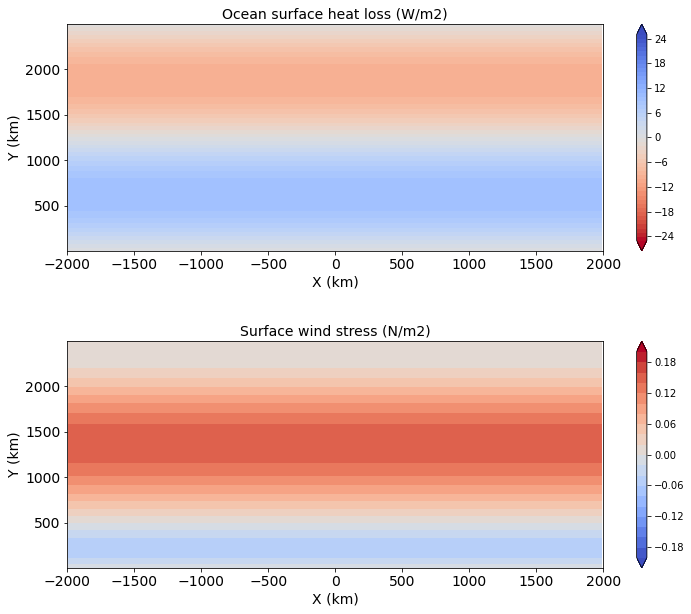

In [9]:
# plot old heat flux and wind stress


# load grid
xx = params_old['xx']
yy = params_old['yy']
XX, YY = np.meshgrid(xx, yy)


# define misc values
secsInYear = 24*3600*365
fz = 14

# plot heat flux
hf_vmin, hf_vmax = -25, 25
hf_clvls = np.arange(hf_vmin, hf_vmax+0.1, 1)


fig, axes = plt.subplots(2, 1, figsize=(12,10))

plt.sca(axes[0])
im = plt.contourf(XX/1e3, YY/1e3, qf_old, hf_clvls, vmin=hf_vmin, 
                      vmax=hf_vmax, cmap=plt.cm.coolwarm_r, extend='both')
# CS = plt.contour(XX/1e3, YY/1e3, qf_old, np.arange(25, 250, 25), 
#                      colors='k') # NBC comments 8/6/2024
# plt.clabel(CS, CS.levels, inline=True, fontsize=fz-6)

plt.xticks(np.arange(-2000, 2001, 500))
plt.tick_params(axis='both', which='major', labelsize=fz)
plt.ylabel("Y (km)", fontsize=fz)
plt.xlabel("X (km)", fontsize=fz)
plt.title("Ocean surface heat loss (W/m2)", fontsize=fz)
plt.colorbar(im, ax=axes[0])

# plot wind stress flux
ws_vmin, ws_vmax = -0.2, 0.2
ws_clvls = np.arange(ws_vmin, ws_vmax+0.001, 0.02)

plt.sca(axes[1])
im = plt.contourf(XX/1e3, YY/1e3, taux_old, ws_clvls, vmin=ws_vmin, 
                      vmax=ws_vmax, cmap=plt.cm.coolwarm, extend='both')
# plt.clabel(CS, CS.levels, inline=True, fontsize=fz-6)

plt.xticks(np.arange(-2000, 2001, 500))
plt.tick_params(axis='both', which='major', labelsize=fz)
plt.ylabel("Y (km)", fontsize=fz)
plt.xlabel("X (km)", fontsize=fz)
plt.title("Surface wind stress (N/m2)", fontsize=fz)
plt.colorbar(im, ax=axes[1])

plt.subplots_adjust(hspace=0.4)

In [10]:
print("Minimum Taux:", np.round(np.min(taux_old), 2))
print("Maximum Taux:", np.round(np.max(taux_old), 2))
print("Minimum Heat Flux:", np.min(qf_old))
print("Maximum Heat Flux:", np.max(qf_old))

Minimum Taux: -0.05
Maximum Taux: 0.15
Minimum Heat Flux: -10.0
Maximum Heat Flux: 10.0


In [11]:
# domain_params_old = params_old['domain_params'] #
# Ln = domain_params_old['L_sponge'] # length of northern sponge layer
# Ys = domain_params_old['SS_slope_Y'] # location of shelf break 

## for some reason, domain_params was not saved for this run, but the code above should generally work
# we will manually enter the domain parameters for now.
Ln = 100e3 # length of northern sponge layer <--update with the appropriate values
Ys = 300e3 # location of shelf break <--update with the appropriate values
Ly = params_old['Ly']

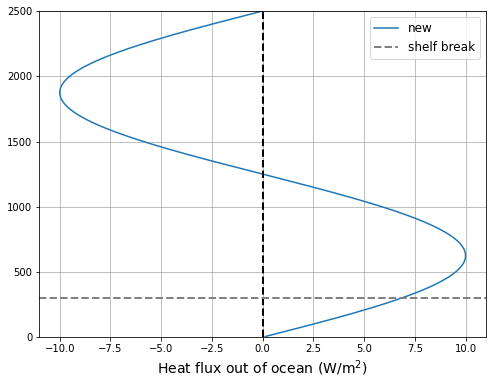

In [12]:
### note: Here and below, I copied over the code from "model_setup_exp_channel_500_250_10km" and made some updates

# #Q is ocean heat loss.
# Q_min=-10 #W/m2 peak surface warming
# Q_max=10 #W/m2 peak surface cooling
# Y_Q0=Ly*0.4 # latitude where Q = 0 W/m2

# # specify heat flux out of the ocean
# qflux_pts = {}
# qflux_pts['yy'] = np.array([0, Ys, Y_Q0, Ly*0.65, Ly-Ln, Ly])
# qflux_pts['values'] = np.array([0, Q_max*0.99, 0, Q_min*0.99, 0, 0]) 

# spl = make_interp_spline(qflux_pts['yy'], qflux_pts['values'], k=3)  # type: BSpline
# qflux = spl(yy)

# qflux[yy>(Ly-Ln)] = 0 # set forcing to zero over sponge layer


# #----------plot heat flux profile
# plt.figure(figsize=(8, 6))
# plt.plot(qflux, yy/1e3, label='new')
# plt.plot(qflux_pts['values'], qflux_pts['yy']/1e3, 'or')
# plt.axvline(0, linestyle='--', linewidth=2, color='k')
# plt.axhline(Ys/1e3, linestyle='--', linewidth=2, color='0.5', label='shelf break')
# #plt.xlim(-10, 20)
# plt.xlabel("Heat flux out of ocean (W/m$^2$)", fontsize=fz)
# plt.grid(True)
# plt.ylim(0, Ly/1e3)
# plt.legend(loc=0, fontsize=fz-2)
# ax1 = plt.gca()
# plt.show()

## NBC major comments to make the same as the actual runs you've used
q0 = 10
q0_shel_anom = 50 
Ly_shelf = Ly
q = q0*(np.sin(2*np.pi*yy/Ly)) # again use simple sinusoid
# q = q0_shel_anom*np.exp(-((yy+5e3)/Ly_shelf)**2)


#----------plot heat flux profile
plt.figure(figsize=(8, 6))
plt.plot(q, yy/1e3, label='new')
#plt.plot(qflux_pts['values'], qflux_pts['yy']/1e3, 'or')
plt.axvline(0, linestyle='--', linewidth=2, color='k')
plt.axhline(Ys/1e3, linestyle='--', linewidth=2, color='0.5', label='shelf break')
#plt.xlim(-10, 20)
plt.xlabel("Heat flux out of ocean (W/m$^2$)", fontsize=fz)
plt.grid(True)
plt.ylim(0, Ly/1e3)
plt.legend(loc=0, fontsize=fz-2)
ax1 = plt.gca()
plt.show()

# Figure 2a)

Wind Stress, Perturbation Wind Stress, Difference, and Buoyancy Surface Boundary Conditions on 1 plot

Control profile reconstructed
Control min (westerly): -0.050807 N/m²
Control max (easterly): 0.153042 N/m²

Bump perturbation created
Bump max: 0.037500 N/m²
Bump center: 1375 km

Contraction perturbation created
Original westerly max magnitude: 0.153042, Final: 0.153042
Optimal amplitude: 0.027658

Northward shift: no-perturbation threshold at Y = 1000.0 km
Original minimum westerly wind stress: -0.050807 N/m²
Optimal scaling factor: 1.017969
Final minimum westerly wind stress: -0.050807 N/m²
Difference: 0.00e+00 N/m²

PERTURBATION SUMMARY
Bump max perturbation: 0.037500 N/m²
Contraction max perturbation: 0.027146 N/m²
Shift max perturbation: 0.019601 N/m²


/share/software/user/open/py-jupyterlab/2.3.2_py36/lib/python3.6/site-packages/ipykernel_launcher.py:169: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray


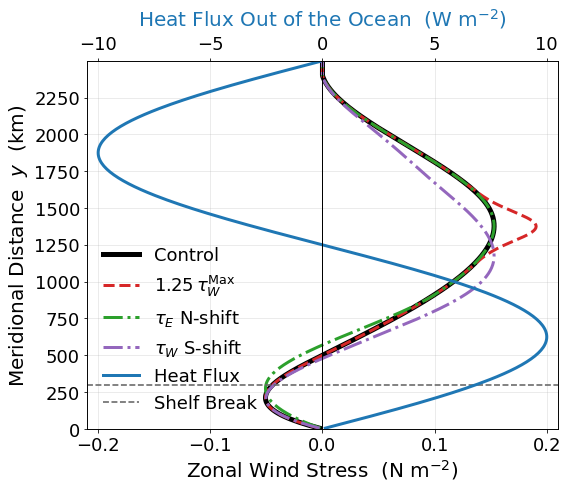

In [20]:
# ============================================================================
# Code for wind stress perturbation plotting
# ============================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import make_interp_spline
from scipy.optimize import fsolve

# Set Verdana font for the entire figure
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Verdana', 'DejaVu Sans', 'Arial']

# ============================================================================
# STEP 1: Reconstruct the original control profile
# ============================================================================

tau_east_max = 0.15
tau_west_max = 0.05
Y_tau0 = Ly * 0.2  # latitude where tau=0

# Control zonal wind stress
taux_pts0 = {}
taux_pts0['yy'] = np.array([0, Y_tau0/2, Y_tau0, Ly*0.6, Ly-Ln, Ly])
taux_pts0['values'] = np.array([-tau_west_max*0, -tau_west_max*0.99, 0, tau_east_max*0.99, 0, 0])

spl0 = make_interp_spline(taux_pts0['yy'], taux_pts0['values'], k=3) 
taux_control = spl0(yy)
taux_control[yy > (Ly-Ln)] = 0  # set forcing to zero over sponge layer

print("Control profile reconstructed")
print(f"Control min (westerly): {np.min(taux_control):.6f} N/m²")
print(f"Control max (easterly): {np.max(taux_control):.6f} N/m²")

# ============================================================================
# STEP 2: Create Perturbation #1 - Gaussian Bump (at y=1375 km)
# ============================================================================

def gaussian(x, mu, sig):
    """Standard Gaussian function"""
    return np.exp(-np.power((x - mu) / sig, 2.0) / 2)

mu_bump = 1375  # km
sig_bump = 90   # km
bump_amplitude = tau_east_max / 4  # 25% of max

bump_pert = gaussian(yy/1e3, mu_bump, sig_bump) * bump_amplitude

print(f"\nBump perturbation created")
print(f"Bump max: {np.max(bump_pert):.6f} N/m²")
print(f"Bump center: {mu_bump} km")

# ============================================================================
# STEP 3: Create Perturbation #2 - Contraction (magnitude-preserving)
# ============================================================================

def create_gaussian_perturbation(yy, mu, sigma, amplitude, bounds=None, sponge_start=None):
    """
    Create a Gaussian perturbation with optional bounds and sponge layer protection
    """
    y_km = yy/1e3
    perturbation = amplitude * np.exp(-np.power((y_km - mu) / sigma, 2.0) / 2)
    
    if bounds is not None:
        y_min, y_max = bounds
        perturbation[(y_km < y_min) | (y_km > y_max)] = 0
    
    if sponge_start is not None:
        perturbation[yy >= sponge_start] = 0
        
    return perturbation

def create_contraction_with_preserved_max(yy, base_profile, shift_distance=700,
                                          new_center_offset=-100, sigma=250,
                                          sponge_start=None, tolerance=1e-8):
    """
    Iteratively finds the correct amplitude to preserve maximum westerly value
    """
    westerly_mask = base_profile > 0
    original_max = np.max(base_profile[westerly_mask])  # Remove np.abs()
    max_idx = np.where(westerly_mask)[0][np.argmax(np.abs(base_profile[westerly_mask]))]
    max_y = yy[max_idx]/1e3
    new_center = max_y + new_center_offset
    
    def objective(amplitude):
        """Find amplitude that gives us the original maximum westerly magnitude"""
        south = create_gaussian_perturbation(yy, new_center - shift_distance/2,
                                            sigma, amplitude, sponge_start=sponge_start)
        north = create_gaussian_perturbation(yy, new_center + shift_distance/2,
                                            sigma, -amplitude, sponge_start=sponge_start)
        combined = south + north
        new_profile = base_profile + combined
        new_max = np.max(new_profile[westerly_mask])  # Remove np.abs()
        return new_max - original_max
    
    optimal_amp = fsolve(objective, 0.015)[0]
    
    south_pert = create_gaussian_perturbation(yy, new_center - shift_distance/2,
                                              sigma, optimal_amp, sponge_start=sponge_start)
    north_pert = create_gaussian_perturbation(yy, new_center + shift_distance/2,
                                              sigma, -optimal_amp, sponge_start=sponge_start)
    combined_pert = south_pert + north_pert
    
    final_profile = base_profile + combined_pert
    final_max = np.max(final_profile[westerly_mask])
    print(f"\nContraction perturbation created")
    print(f"Original westerly max magnitude: {original_max:.6f}, Final: {final_max:.6f}")
    print(f"Optimal amplitude: {optimal_amp:.6f}")
    
    return south_pert, north_pert, combined_pert

sponge_start = Ly - Ln
south_pert, north_pert, contraction_pert = create_contraction_with_preserved_max(
    yy, taux_control, 
    shift_distance=700, 
    new_center_offset=-100, 
    sigma=250, 
    sponge_start=sponge_start
)

# ============================================================================
# STEP 4: Create Perturbation #3 - Northward Shift (magnitude-preserving)
# ============================================================================

# Calculate control wind stress curl
dtaux_dy0 = np.gradient(taux_control, yy, edge_order=2)

def find_zero_crossings(curl, yy, threshold=1e-10):
    """Find locations where curl crosses zero"""
    zero_crossings = []
    
    for i in range(len(curl)-1):
        if abs(curl[i]) > threshold and abs(curl[i+1]) > threshold:
            if curl[i] * curl[i+1] < 0:
                y_cross = yy[i] + (yy[i+1] - yy[i]) * (-curl[i]) / (curl[i+1] - curl[i])
                zero_crossings.append(y_cross)
    
    return np.array(zero_crossings)

zero_crossings = find_zero_crossings(dtaux_dy0, yy)

Y_no_perturb = 1000e3
print(f"\nNorthward shift: no-perturbation threshold at Y = {Y_no_perturb/1e3:.1f} km")

westerly_mask = taux_control < 0
original_min = np.min(taux_control[westerly_mask])
print(f"Original minimum westerly wind stress: {original_min:.6f} N/m²")

shift_n = 75e3

tau_east_max_original = tau_east_max
tau_west_max_original = tau_west_max

def create_perturbed_profile_shift(scale_factor):
    """Create perturbed wind stress profile with a scaling factor"""
    tau_east_scaled = tau_east_max_original * scale_factor
    tau_west_scaled = tau_west_max_original * scale_factor
    
    taux_pts = {}
    taux_pts['yy'] = np.array([0+0, Y_tau0/2, 300e3+shift_n, 900e3, 950e3, Y_no_perturb, Ly*0.6, Ly-Ln, Ly])
    taux_pts['values'] = np.array([-tau_west_scaled*0, 
                                    -tau_west_scaled*0.99, 
                                    spl0(300e3),
                                    spl0(900e3),
                                    spl0(950e3),
                                    spl0(Y_no_perturb),
                                    tau_east_scaled*0.99, 
                                    0, 
                                    0])
    
    spl_temp = make_interp_spline(taux_pts['yy'], taux_pts['values'], k=3) 
    taux_temp = spl_temp(yy)
    taux_temp[yy > (Ly-Ln)] = 0
    taux_temp[yy > Y_no_perturb] = taux_control[yy > Y_no_perturb]
    
    new_min = np.min(taux_temp[westerly_mask])
    
    return new_min - original_min

optimal_scale = fsolve(create_perturbed_profile_shift, 1.0)[0]
print(f"Optimal scaling factor: {optimal_scale:.6f}")

tau_east_max_scaled = tau_east_max_original * optimal_scale
tau_west_max_scaled = tau_west_max_original * optimal_scale

taux_pts_shift = {}
taux_pts_shift['yy'] = np.array([0+0, Y_tau0/2, 300e3+shift_n, 900e3, 950e3, Y_no_perturb, Ly*0.6, Ly-Ln, Ly])
taux_pts_shift['values'] = np.array([-tau_west_max_scaled*0, 
                                -tau_west_max_scaled*0.99, 
                                spl0(300e3),
                                spl0(900e3),
                                spl0(950e3),
                                spl0(Y_no_perturb),
                                tau_east_max_scaled*0.99, 
                                0, 
                                0])

spl_shift = make_interp_spline(taux_pts_shift['yy'], taux_pts_shift['values'], k=3) 
taux_shift = spl_shift(yy)
taux_shift[yy > (Ly-Ln)] = 0
taux_shift[yy > Y_no_perturb] = taux_control[yy > Y_no_perturb]

shift_pert = taux_shift - taux_control

final_min = np.min(taux_shift[westerly_mask])
print(f"Final minimum westerly wind stress: {final_min:.6f} N/m²")
print(f"Difference: {abs(final_min - original_min):.2e} N/m²")

print("\n" + "="*60)
print("PERTURBATION SUMMARY")
print("="*60)
print(f"Bump max perturbation: {np.max(bump_pert):.6f} N/m²")
print(f"Contraction max perturbation: {np.max(np.abs(contraction_pert)):.6f} N/m²")
print(f"Shift max perturbation: {np.max(np.abs(shift_pert)):.6f} N/m²")

# ============================================================================
# STEP 5: PLOTTING
# ============================================================================

fz = 20
fig, ax_tau = plt.subplots(figsize=(8, 6.9))          # bottom axis → wind stress

# ─────────────────────────────────────────
# 1.  WIND-STRESS PROFILES  (bottom axis)
# ─────────────────────────────────────────
ax_tau.plot(taux_control, yy/1e3, lw=5, color='k', label='Control')
ax_tau.plot(taux_control + bump_pert, yy/1e3, lw=3, color='tab:red', linestyle='--',  
            label=r'$1.25\,\tau_W^{\mathrm{Max}}$')
ax_tau.plot(taux_control + shift_pert, yy/1e3, lw=3, color='tab:green', linestyle='-.',  
            label=r'$\tau_E$ N-shift')
ax_tau.plot(taux_control + contraction_pert, yy/1e3, lw=3, color='tab:purple', linestyle='-.',  
            label=r'$\tau_W$ S-shift')

ax_tau.set_xlabel(r'Zonal Wind Stress  (N m$^{-2}$)', fontsize=fz)
ax_tau.set_xlim(1.05*-0.2, 1.05*0.2)
ax_tau.set_ylabel('Meridional Distance  $y$  (km)', fontsize=fz)
ax_tau.set_ylim(0, Ly/1e3)
ax_tau.set_yticks(np.arange(0, 2500, 250))
ax_tau.grid(True, alpha=0.3)

# Shelf-break reference (shared line; label goes to legend later)
shelf_line = ax_tau.axhline(Ys/1e3, ls='--', lw=1.6, c='0.4', label='Shelf Break')

# ─────────────────────────────────────────
# 2.  HEAT-FLUX PROFILE  (top twin axis)
# ─────────────────────────────────────────
ax_heat = ax_tau.twiny()                           # new axis on top
ax_heat.plot(q, yy/1e3, lw=3, color='tab:blue', label='Heat Flux')
ax_heat.axvline(0, ls='-', lw=1, c='k')

ax_heat.set_xlabel(r'Heat Flux Out of the Ocean  (W m$^{-2}$)',
                   fontsize=fz, labelpad=10, color='tab:blue')

ax_heat.set_xlim(np.nanmin(q)*1.05, np.nanmax(q)*1.05)
ax_heat.xaxis.set_ticks_position('top')
ax_heat.xaxis.set_label_position('top')

# ─────────────────────────────────────────
# 3.  Legend — "Shelf Break" last
# ─────────────────────────────────────────
handles, labels = [], []
for ax in (ax_tau, ax_heat):
    h, l = ax.get_legend_handles_labels()
    handles.extend(h)
    labels.extend(l)

idx = labels.index('Shelf Break')      # move shelf-break entry to the end
handles.append(handles.pop(idx))
labels.append(labels.pop(idx))

ax_tau.legend(handles, labels, loc='lower left', fontsize=fz-2, frameon=False)

tick_sz = 18

for ax in (ax_tau, ax_heat):    # both x-axes share the same y-axis
    ax.tick_params(axis='both',      # affect x and y
                   which='major',    # major ticks (default)
                   labelsize=tick_sz)

fig.tight_layout()

# save first …
fig.savefig('branch_4_SurfBC_nocolons_updateall3.pdf',
            dpi=300,
            bbox_inches='tight',
            facecolor='white')  # Add this parameter for white background

# … then show (optional in notebooks)
plt.show()